# 🧪 Step 3: 비정형 응급실 초진 노이즈 스트레스 테스트 (`N=40`)
### 구어체·배경 잡음(Distractor)·간접 임상 묘사 환경에서의 `T_orig` vs `T_opt` 강건성 검증

* **테스트셋**: `data/benchmark/ktas_noisy_cases.json` (중증 1~2등급 20건 + 경증 3~5등급 20건)
* **검증 목적**: 정형 규칙 키워드가 직접 노출되지 않은 현실적인 간호사 초진 기록에서도 `T_opt`가 정확도·임상 안전성(Under-triage 억제)·경로 충실도·토큰 효율 우위를 유지하는지 검증


---
## 1. 원본 정형 입력 vs 변환된 비정형 노이즈 텍스트 샘플 대조 표


In [1]:
# Step 1: 환경 설정 및 원본 vs 노이즈 텍스트 대조 표 출력
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CWD = Path.cwd()
if (CWD / "src" / "benchmark").exists():
    EXP_ROOT = CWD
elif (CWD.parent / "src" / "benchmark").exists():
    EXP_ROOT = CWD.parent
else:
    EXP_ROOT = Path("/home/meisteryi/문서/KTAS-LLM/experiments/03_tree_structure_optimization")

sys.path.insert(0, str(EXP_ROOT / "src" / "benchmark"))
sys.path.insert(0, str(EXP_ROOT / "src" / "optimizer"))

from run_llm_benchmark import (
    InferenceBackend,
    build_ab_report,
    build_user_prompt,
    compute_metrics,
    load_orig_complaint_map,
    mcnemar_pvalue,
    parse_llm_json,
    serialize_t_opt_context,
    serialize_t_orig_context,
    wilcoxon_pvalue,
)

plt.rcParams["font.family"] = "Noto Sans CJK KR"
plt.rcParams["axes.unicode_minus"] = False

RAW_DIR = EXP_ROOT / "data" / "raw"
OPT_JSON = EXP_ROOT / "data" / "optimized" / "ktas_optimized_tree.json"
NOISY_JSON = EXP_ROOT / "data" / "benchmark" / "ktas_noisy_cases.json"
OUT_JSONL = EXP_ROOT / "data" / "benchmark" / "noisy_ab_raw_results.jsonl"
REPORTS_DIR = EXP_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with NOISY_JSON.open("r", encoding="utf-8") as f:
    noisy_cases = json.load(f)
with OPT_JSON.open("r", encoding="utf-8") as f:
    opt_data = json.load(f)

pd.set_option("display.max_colwidth", 180)
sample_df = pd.DataFrame([
    {
        "ID": c["case_id"],
        "주호소": f"{c['context']} {c['complaint_name']} ({c['nacrs_code']})",
        "정답 등급": f"{c['ground_truth_level']}단계",
        "원본 정형 입력": c["original_presentation"],
        "비정형 노이즈 변환 입력": c["patient_presentation"],
    }
    for c in noisy_cases[:5]
])
print(f"[+] 비정형 노이즈 케이스 로드: 총 {len(noisy_cases)}건 (중증 1~2등급: {sum(1 for c in noisy_cases if c['ground_truth_level'] in (1,2))}건)")
display(sample_df)


[+] 비정형 노이즈 케이스 로드: 총 40건 (중증 1~2등급: 20건)


/home/meisteryi/문서/KTAS-LLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,ID,주호소,정답 등급,원본 정형 입력,비정형 노이즈 변환 입력
0,NOISY_001,ADULT 인후통 (103),2단계,"[만 50세 성인] 주호소: 인후통 (NACRS 103). 1차 활력징후는 특이 위험 징후 없으나, 문진 및 진찰상 다음 2차 세부 소견이 확인됨: 협착음 (급성 후두개염 의심).",[응급실 초진 간호기록] 31세 환자가 '인후통' 문제로 내원함. 보호자(배우자)와 함께 도보로 내원하였으며 평소 고혈압 약을 아침에 복용했다고 함. 초기 사정 및 문진에서 확인된 핵심 소견으로는 협착음 [급성 후두개염 의심] 등이 보고됨. 추가적인 특이 증상 호소는 없음.
1,NOISY_002,PED 심정지 (외상성) (002),5단계,"[만 12세 소아] 주호소: 심정지 (외상성) (NACRS 002). 내원 시 확인된 임상 상태: 심정지 (외상성), 심폐소생술의 대상이 아닌 경우. 의식/호흡/순환 평가와 함께 연명의료결정(DNR) 여부를 우선 확인함.",[응급실 초진 간호기록] 12세 환아가 '심정지 (외상성)' 문제로 내원함. 119 구급차 대신 자가용을 이용해 응급실로 내원하였으며 보호자가 접수를 진행함. 초기 사정 및 문진에서 확인된 핵심 소견으로는 심정지 [외상성]; 심폐소생술의 대상이 아닌 경우 등이 보고됨. 추가적인 특이 증상 호소는 없음.
2,NOISY_003,ADULT 코의 외상 (155),2단계,[만 74세 성인] 주호소: 코의 외상 (NACRS 155). 초기 활력징후 및 1차 고려사항 평가 결과: 출혈성 질환(위급한 출혈). 해당 주호소의 기타 2차 세부 증상은 특이 소견 없음.,[응급실 초진 간호기록] 60세 환자가 '코의 외상' 문제로 내원함. 대기실에서 물을 한 모금 마신 뒤 접수하였으며 최근 감기 기운이 있었다고 언급함. 초기 사정 및 문진에서 확인된 핵심 소견으로는 평소 항응고제[와파린]를 복용 중인 환자로 지혈이 되지 않는 다량의 출혈 소견한 출혈] 등이 보고됨. 추가적인 특이 ...
3,NOISY_004,PED 옆구리 통증 (301),3단계,"[만 2세 소아] 주호소: 옆구리 통증 (NACRS 301). 1차 활력징후는 특이 위험 징후 없으나, 문진 및 진찰상 다음 2차 세부 소견이 확인됨: 소아 1차 활력징후 3단계, 중등도 통증 (4-7), 만성 3단계, 만성 경증 옆구리 통증.","[응급실 초진 간호기록] 7세 환아가 '옆구리 통증' 문제로 내원함. 과거 5년 전 타 병원에서 단순 건강검진을 받은 적 있고 최근 해외여행력은 없음. 초기 사정 및 문진에서 확인된 핵심 소견으로는 활력징후가 정상 상·하한 경계에 걸려 있거나 미열과 경미한 숨참이 동반되나 의식은 명료함, 중등도 통증 [4-7], ..."
4,NOISY_005,PED 복통 (251),4단계,"[만 5세 소아] 주호소: 복통 (NACRS 251). 1차 활력징후는 특이 위험 징후 없으나, 문진 및 진찰상 다음 2차 세부 소견이 확인됨: 소아 1차 활력징후 4단계, 급성 경증 통증 (<4), 만성 4단계.","[응급실 초진 간호기록] 11세 환아가 '복통' 문제로 내원함. 119 구급차 대신 자가용을 이용해 응급실로 내원하였으며 보호자가 접수를 진행함. 초기 사정 및 문진에서 확인된 핵심 소견으로는 미열만 살짝 있으나 전반적으로 활력징후가 안정적이고 대화에 무리가 없음, 살짝 욱신거리는 정도의 참을 만한 경미한 통증[통..."


---
## 2. 비정형 노이즈 환경 `T_orig` vs `T_opt` A/B 추론 실행 (`N=40`, 80회 추론)


In [2]:
# Step 2: 노이즈 스트레스 테스트 A/B 추론 실행 (중단 재개 지원)
BACKEND = "auto"
BASE_URL = None
MODEL_ARG = ""

existing_records = []
done_keys = set()
if OUT_JSONL.exists():
    with OUT_JSONL.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rec = json.loads(line)
                existing_records.append(rec)
                done_keys.add((rec["case_id"], rec["tree_variant"]))

orig_map = load_orig_complaint_map(RAW_DIR)
opt_map = {(c["context"], c["nacrs_code"], c["name"]): c for c in opt_data["complaints"]}

tasks = []
for c in noisy_cases:
    key = (c["context"], c["nacrs_code"], c["complaint_name"])
    if (c["case_id"], "T_orig") not in done_keys:
        tasks.append((c, "T_orig", serialize_t_orig_context(orig_map[key])))
    if (c["case_id"], "T_opt") not in done_keys:
        tasks.append((c, "T_opt", serialize_t_opt_context(opt_map[key])))

print(f"[*] 기존 완료: {len(done_keys)}회 | 신규 추론 필요: {len(tasks)}회")

if tasks:
    engine = InferenceBackend(BACKEND, MODEL_ARG, BASE_URL)
    with OUT_JSONL.open("a", encoding="utf-8") as f:
        for idx, (c, variant, tree_ctx) in enumerate(tasks, start=1):
            t0 = time.perf_counter()
            prompt = build_user_prompt(c, tree_ctx)
            raw_out, in_toks, out_toks = engine.generate(prompt)
            elapsed = time.perf_counter() - t0
            parsed = parse_llm_json(raw_out)
            rec = {
                "case_id": c["case_id"],
                "tree_variant": variant,
                "ground_truth_level": c["ground_truth_level"],
                "input_tokens": in_toks,
                "output_tokens": out_toks,
                "elapsed_sec": round(elapsed, 3),
                "parsed": parsed,
                "raw_output": raw_out,
            }
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            existing_records.append(rec)

print(f"[+] 총 로드된 노이즈 평가 레코드: {len(existing_records)}건")


[*] 기존 완료: 80회 | 신규 추론 필요: 0회
[+] 총 로드된 노이즈 평가 레코드: 80건


---
## 3. 노이즈 환경 정량 비교 표 및 시각화 그래프


,지표,T_orig,T_opt,Delta,p-value
0,최종 등급 정확도 (% ↑),82.50,92.50,10.00,0.2188
1,"치명적 과소평가율 (1~2➔3~5, % ↓)",10.00,5.00,-5.00,1.0000
2,과대평가율 (% ↓),5.00,0.00,-5.00,-
3,전체 1차 축 누락률 (% ↓),45.71,17.14,-28.57,0.0020
4,근거 규칙 일치율 (% ↑),85.71,92.86,7.14,-
5,환자당 총 토큰 (↓),1305.80,1053.70,-252.10,0.0000


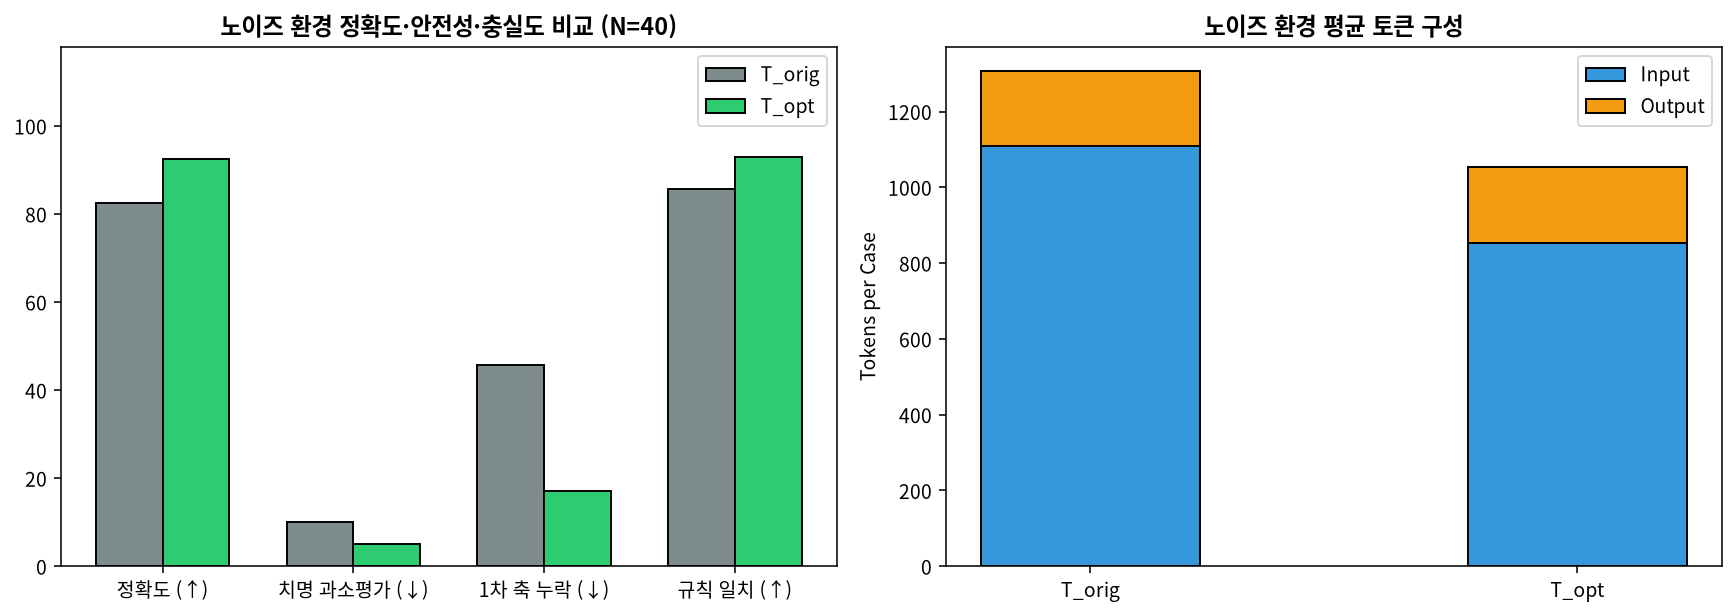

In [3]:
# Step 3: 지표 비교 표, 통계 검정, 시각화 그래프 및 마크다운 저장
cases_by_id = {c["case_id"]: c for c in noisy_cases}
r_orig = [r for r in existing_records if r["tree_variant"] == "T_orig"]
r_opt = [r for r in existing_records if r["tree_variant"] == "T_opt"]

mo = compute_metrics(r_orig, cases_by_id)
mp = compute_metrics(r_opt, cases_by_id)

if mo and mp:
    vo, vp = mo["_vecs"], mp["_vecs"]
    p_acc = mcnemar_pvalue(vo["acc"], vp["acc"])
    p_cu = mcnemar_pvalue(vo["crit_under"], vp["crit_under"])
    p_ma = mcnemar_pvalue(vo["miss_all"], vp["miss_all"])
    p_tot = wilcoxon_pvalue(vo["tot_toks"], vp["tot_toks"])

    comp_df = pd.DataFrame([
        {"지표": "최종 등급 정확도 (% ↑)", "T_orig": round(mo["acc"], 2), "T_opt": round(mp["acc"], 2), "Delta": round(mp["acc"] - mo["acc"], 2), "p-value": f"{p_acc:.4f}" if p_acc is not None else "-"},
        {"지표": "치명적 과소평가율 (1~2➔3~5, % ↓)", "T_orig": round(mo["crit_under_triage"], 2), "T_opt": round(mp["crit_under_triage"], 2), "Delta": round(mp["crit_under_triage"] - mo["crit_under_triage"], 2), "p-value": f"{p_cu:.4f}" if p_cu is not None else "-"},
        {"지표": "과대평가율 (% ↓)", "T_orig": round(mo["over_triage"], 2), "T_opt": round(mp["over_triage"], 2), "Delta": round(mp["over_triage"] - mo["over_triage"], 2), "p-value": "-"},
        {"지표": "전체 1차 축 누락률 (% ↓)", "T_orig": round(mo["missing_first_all"], 2), "T_opt": round(mp["missing_first_all"], 2), "Delta": round(mp["missing_first_all"] - mo["missing_first_all"], 2), "p-value": f"{p_ma:.4f}" if p_ma is not None else "-"},
        {"지표": "근거 규칙 일치율 (% ↑)", "T_orig": round(mo["rule_cite_acc"], 2), "T_opt": round(mp["rule_cite_acc"], 2), "Delta": round(mp["rule_cite_acc"] - mo["rule_cite_acc"], 2), "p-value": "-"},
        {"지표": "환자당 총 토큰 (↓)", "T_orig": round(mo["avg_tot"], 1), "T_opt": round(mp["avg_tot"], 1), "Delta": round(mp["avg_tot"] - mo["avg_tot"], 1), "p-value": f"{p_tot:.4f}" if p_tot is not None else "-"},
    ])
    display(comp_df)

    # 리포트 저장
    report_md = build_ab_report(existing_records, cases_by_id, "Qwen2.5-32B-Instruct (Noisy Stress Test N=40)")
    (REPORTS_DIR / "noisy_stress_test_results.md").write_text(report_md, encoding="utf-8")

    # 시각화
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), dpi=140)
    labels = ["정확도 (↑)", "치명 과소평가 (↓)", "1차 축 누락 (↓)", "규칙 일치 (↑)"]
    v0 = [mo["acc"], mo["crit_under_triage"], mo["missing_first_all"], mo["rule_cite_acc"]]
    v1 = [mp["acc"], mp["crit_under_triage"], mp["missing_first_all"], mp["rule_cite_acc"]]
    x = np.arange(len(labels))
    w = 0.35
    axes[0].bar(x - w / 2, v0, w, label="T_orig", color="#7f8c8d", edgecolor="black")
    axes[0].bar(x + w / 2, v1, w, label="T_opt", color="#2ecc71", edgecolor="black")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(labels)
    axes[0].set_ylim(0, 118)
    axes[0].set_title("노이즈 환경 정확도·안전성·충실도 비교 (N=40)", fontweight="bold")
    axes[0].legend()

    axes[1].bar(["T_orig", "T_opt"], [mo["avg_in"], mp["avg_in"]], width=0.45, label="Input", color="#3498db", edgecolor="black")
    axes[1].bar(["T_orig", "T_opt"], [mo["avg_out"], mp["avg_out"]], width=0.45, bottom=[mo["avg_in"], mp["avg_in"]], label="Output", color="#f39c12", edgecolor="black")
    axes[1].set_title("노이즈 환경 평균 토큰 구성", fontweight="bold")
    axes[1].set_ylabel("Tokens per Case")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(REPORTS_DIR / "noisy_stress_test_dashboard.png", bbox_inches="tight", dpi=150)
    plt.show()


---
## 4. 노이즈에 흔들린 오분류 사례 분석


In [4]:
# Step 4: 노이즈 환경에서 오분류가 발생한 사례 추출 및 원인 출력
orig_by_id = {r["case_id"]: r for r in r_orig}
opt_by_id = {r["case_id"]: r for r in r_opt}

err_ids = []
for cid in sorted(set(orig_by_id) & set(opt_by_id)):
    gt = cases_by_id[cid]["ground_truth_level"]
    lo = int(orig_by_id[cid]["parsed"].get("final_ktas_level", 0))
    lp = int(opt_by_id[cid]["parsed"].get("final_ktas_level", 0))
    if lo != gt or lp != gt:
        err_ids.append((cid, gt, lo, lp))

print(f"[*] 노이즈 환경 오분류 발생 케이스: 총 {len(err_ids)}건")
for cid, gt, lo, lp in err_ids[:10]:
    c = cases_by_id[cid]
    po, pp = orig_by_id[cid]["parsed"], opt_by_id[cid]["parsed"]
    print("=" * 85)
    print(f"🚨 [{cid}] {c['context']} {c['complaint_name']} | 정답={gt}단계 | T_orig={lo}단계 | T_opt={lp}단계")
    print(f"   입력: {c['patient_presentation']}")
    print(f"   T_orig 근거: {po.get('matched_rule_text')} | 축: {po.get('checked_first_order_axes')}")
    print(f"   T_opt  근거: {pp.get('matched_rule_text')} | 축: {pp.get('checked_first_order_axes')}")


[*] 노이즈 환경 오분류 발생 케이스: 총 8건
🚨 [NOISY_007] PED 20주 미만의 임신 | 정답=2단계 | T_orig=5단계 | T_opt=2단계
   입력: [응급실 초진 간호기록] 35세 여성 환자가 '20주 미만의 임신' 문제로 내원함. 내원 3일 전부터 기운이 없고 입맛이 떨어졌다고 진술하며, 약물 알레르기는 부인함. 초기 사정 및 문진에서 확인된 핵심 소견으로는 맥박이 빠르고 혈압이 평소보다 떨어져 있으며 식은땀과 함께 숨이 차고 약간 처지는 양상; 핑크빛 점액성 분비물 또는 질 분비물 등이 보고됨. 추가적인 특이 증상 호소는 없음.
   T_orig 근거: (KTAS 5단계) 핑크빛 점액성 분비물 또는 질 분비물 | 축: ['1차_활력징후', '출혈_양상']
   T_opt  근거: 1차_활력징후 2단계:소아 1차 활력징후 2단계 만족 | 축: ['1차_활력징후', '시간/경과기간']
🚨 [NOISY_008] ADULT 전문 진료를 위해서 의뢰된 환자 | 정답=3단계 | T_orig=4단계 | T_opt=4단계
   입력: [응급실 초진 간호기록] 62세 환자가 '전문 진료를 위해서 의뢰된 환자' 문제로 내원함. 과거 5년 전 타 병원에서 단순 건강검진을 받은 적 있고 최근 해외여행력은 없음. 초기 사정 및 문진에서 확인된 핵심 소견으로는 활력징후가 정상 상·하한 경계에 걸려 있거나 미열과 경미한 숨참이 동반되나 의식은 명료함, 중심성/말초성 통증 3단계, 만성 3단계; 미열만 살짝 있으나 전반적으로 활력징후가 안정적이고 대화에 무리가 없음, 중심성/말초성 통증 4단계, 만성 4단계 등이 보고됨. 추가적인 특이 증상 호소는 없음.
   T_orig 근거: (KTAS 4단계) 1차 활력징후 4단계, 중심성/말초성 통증 4단계, 만성 4단계 | 축: ['1차_활력징후', '통증_척도']
   T_opt  근거: [1차_활력징후] 4단계:1차 활력징후 4단계, 중심성/말초성 통증 4단계, 만성 4단계 | 축: ['1차_활력징후', '통증_